<a href="https://colab.research.google.com/github/PriyankaDardemal/AI_PRACTICALS/blob/main/Smart_Waste_Collection_Optimization_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import itertools
import matplotlib.pyplot as plt

print("Smart Waste Collection Optimization")
print("Libraries imported successfully!")

Smart Waste Collection Optimization
Libraries imported successfully!


In [2]:

locations = {
    "A": (0, 0),   # Depot
    "B": (2, 4),
    "C": (5, 5),
    "D": (6, 1),
    "E": (1, 2)
}

# Distance matrix in kilometres
distance = [
    [0, 5, 8, 7, 3],
    [5, 0, 4, 6, 3],
    [8, 4, 0, 5, 6],
    [7, 6, 5, 0, 6],
    [3, 3, 6, 6, 0]
]

names = list(locations.keys())

print("Locations:", names)
print("Total locations:", len(names))

Locations: ['A', 'B', 'C', 'D', 'E']
Total locations: 5


In [3]:

best_route = None
minimum_distance = float("inf")

# A is the depot; B, C, D and E are collection points
collection_points = names[1:]

for route in itertools.permutations(collection_points):
    complete_route = ("A",) + route + ("A",)

    total = 0

    for i in range(len(complete_route) - 1):
        source = names.index(complete_route[i])
        destination = names.index(complete_route[i + 1])

        total += distance[source][destination]

    if total < minimum_distance:
        minimum_distance = total
        best_route = complete_route

print("Optimal route:", " -> ".join(best_route))
print("Minimum distance:", minimum_distance, "km")

Optimal route: A -> D -> C -> B -> E -> A
Minimum distance: 22 km


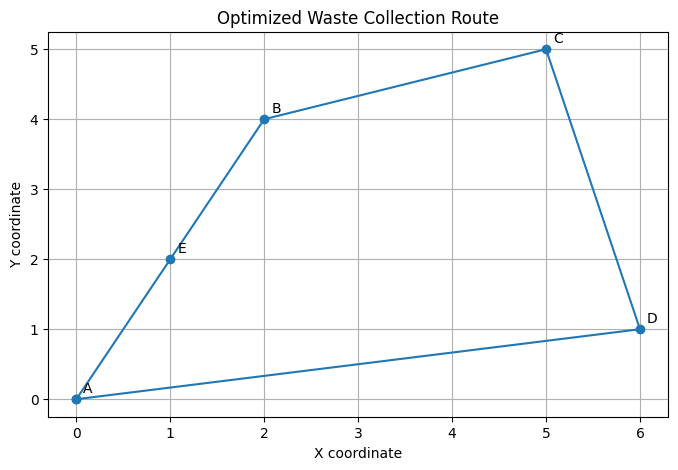

In [4]:

x_values = [locations[p][0] for p in best_route]
y_values = [locations[p][1] for p in best_route]

plt.figure(figsize=(8, 5))
plt.plot(x_values, y_values, marker="o")

for name, (x, y) in locations.items():
    plt.annotate(name, (x, y), xytext=(5, 5),
                 textcoords="offset points")

plt.title("Optimized Waste Collection Route")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.show()

In [5]:

# Original route: A -> B -> C -> D -> E -> A
original_route = names + ["A"]
original_distance = 0

for i in range(len(original_route) - 1):
    source = names.index(original_route[i])
    destination = names.index(original_route[i + 1])
    original_distance += distance[source][destination]

saved_distance = original_distance - minimum_distance
saving_percent = (saved_distance / original_distance) * 100

print("Original distance:", original_distance, "km")
print("Optimized distance:", minimum_distance, "km")
print("Distance saved:", saved_distance, "km")
print("Percentage reduction:", round(saving_percent, 2), "%")

Original distance: 23 km
Optimized distance: 22 km
Distance saved: 1 km
Percentage reduction: 4.35 %
